# 🌏 AirSense India: Recent Air Quality Trends & Next-Day PM2.5 Prediction

**Research questions:** Which cities have higher estimated PM2.5? How does it vary by month? Can yesterday's pollution help predict tomorrow's PM2.5?

## 1. Setup and imports
Install dependencies from `requirements.txt` first, or uncomment the pip line below on Kaggle/Colab.

In [13]:
# %pip install pandas numpy matplotlib seaborn scikit-learn requests
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", palette="crest")
DATA_DIR = Path("data")
OUT = Path("outputs")
DATA_DIR.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
print("Ready")

Ready


## 2. Download and load recent source data
The notebook downloads the latest available source CSV files when run locally. If your Kaggle notebook has Internet disabled, add the [Kaggle dataset](https://www.kaggle.com/datasets/akshaykarthickms007/india-daily-weather-and-air-quality) via **Add Input**; the loader checks `/kaggle/input` automatically.

In [14]:
BASE = "https://huggingface.co/datasets/AkshayKarthick/india-weather-air-quality/resolve/main"

def get_csv(filename):
    local = DATA_DIR / filename
    if local.exists():
        print("Using local", local)
        return pd.read_csv(local)
    kaggle_matches = list(Path("/kaggle/input").rglob(filename)) if Path("/kaggle/input").exists() else []
    if kaggle_matches:
        print("Using Kaggle input", kaggle_matches[0])
        return pd.read_csv(kaggle_matches[0])
    import requests
    url = f"{BASE}/{filename}"
    try:
        r = requests.get(url, timeout=90)
        r.raise_for_status()
        local.write_bytes(r.content)
    except Exception as exc:
        raise RuntimeError(f"Could not download {filename}. Download manually from {BASE} and place it in data/. Original error: {exc}") from exc
    print("Downloaded", filename)
    return pd.read_csv(local)

raw = get_csv("air_quality_daily.csv")
cities = get_csv("cities.csv")
print("Original data shape:", raw.shape)
print("Columns:", raw.columns.tolist())
display(raw.head())

Using local data\air_quality_daily.csv
Using local data\cities.csv
Original data shape: (77250, 19)
Columns: ['date', 'city', 'pm2_5_mean', 'pm2_5_max', 'pm10_mean', 'pm10_max', 'no2_mean', 'so2_mean', 'o3_8h_max', 'co_8h_max', 'dust_mean', 'aod_mean', 'us_aqi_max', 'hours_available', 'india_aqi', 'india_aqi_category', 'dominant_pollutant', 'india_aqi_pm', 'india_aqi_pm_category']


,date,city,pm2_5_mean,pm2_5_max,pm10_mean,pm10_max,no2_mean,so2_mean,o3_8h_max,co_8h_max,dust_mean,aod_mean,us_aqi_max,hours_available,india_aqi,india_aqi_category,dominant_pollutant,india_aqi_pm,india_aqi_pm_category
0,2022-08-05,Agartala,14.09,19.1,20.50,27.6,20.63,2.32,72.00,204.75,0.0,0.18,61.0,24,72,Satisfactory,O3,23,Good
1,2022-08-06,Agartala,12.12,19.3,17.44,27.7,23.11,1.10,48.00,208.00,0.0,0.16,60.0,24,48,Good,O3,20,Good
2,2022-08-07,Agartala,11.85,19.0,17.18,27.6,22.27,1.18,75.00,238.38,0.0,0.15,56.0,24,75,Satisfactory,O3,20,Good
3,2022-08-08,Agartala,9.28,13.5,13.47,19.5,16.25,1.10,65.25,241.38,0.0,0.12,57.0,24,65,Satisfactory,O3,15,Good
4,2022-08-09,Agartala,6.33,7.4,9.25,10.8,11.51,1.28,69.38,181.88,0.0,0.10,51.0,24,69,Satisfactory,O3,11,Good


## 3. Cleaning and scope

In [15]:
required = {"date", "city", "pm2_5_mean", "pm10_mean"}
assert required.issubset(raw.columns), f"Missing columns: {required - set(raw.columns)}"
df = raw.copy()
df["date"] = pd.to_datetime(df["date"], errors="coerce")
for col in ["pm2_5_mean", "pm10_mean", "india_aqi_pm"]:
    if col in df:
        df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.drop_duplicates(subset=["city", "date"])
df = df[df["date"].ge("2025-01-01") & df["date"].le("2026-10-28")]
df = df.dropna(subset=["date", "city", "pm2_5_mean"])
df = df[df["pm2_5_mean"].ge(0)].sort_values(["city", "date"]).reset_index(drop=True)
df["month"] = df["date"].dt.month
df["year"] = df["date"].dt.year
print(f"Records: {len(df):,} | Cities: {df.city.nunique()} | Dates: {df.date.min().date()} to {df.date.max().date()}")
print("Missing percentages (top 10):")
display((df.isna().mean()*100).sort_values(ascending=False).head(10).round(1))
assert len(df) > 0, "No records in the selected date window"

Records: 33,250 | Cities: 50 | Dates: 2025-01-01 to 2026-10-27
Missing percentages (top 10):


date                     0.0
aod_mean                 0.0
month                    0.0
india_aqi_pm_category    0.0
india_aqi_pm             0.0
dominant_pollutant       0.0
india_aqi_category       0.0
india_aqi                0.0
hours_available          0.0
us_aqi_max               0.0
dtype: float64

## 4. EDA — estimated PM2.5 across Indian cities

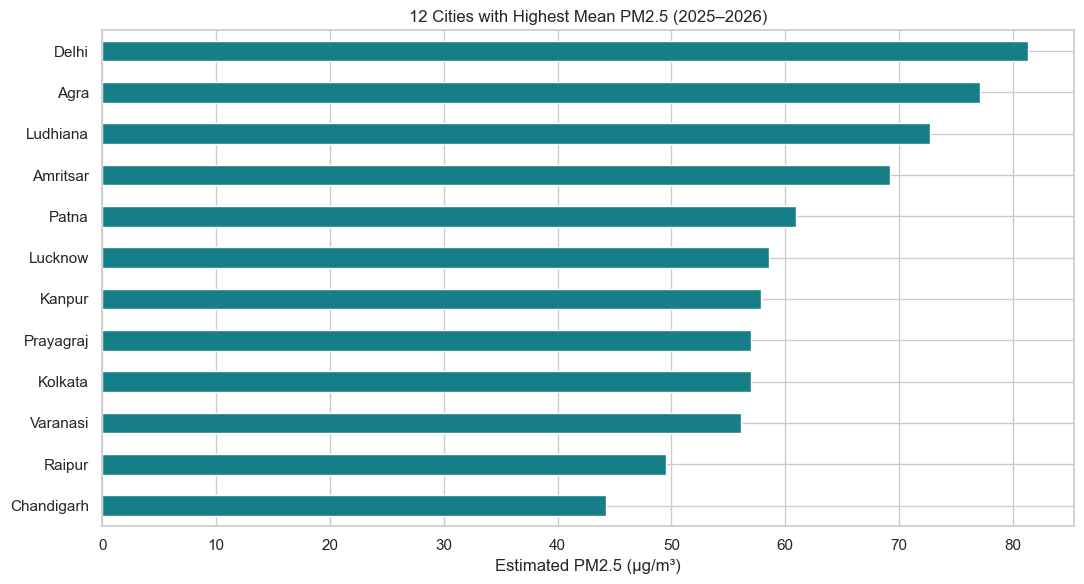

Top 5 cities by estimated mean PM2.5:


,PM2.5 (µg/m³)
city,
Delhi,81.3
Agra,77.1
Ludhiana,72.8
Amritsar,69.2
Patna,60.9


In [16]:
city_avg = df.groupby("city")["pm2_5_mean"].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(11, 6))
city_avg.head(12).sort_values().plot(kind="barh", ax=ax, color="#167e87")
ax.set(title="12 Cities with Highest Mean PM2.5 (2025–2026)", xlabel="Estimated PM2.5 (µg/m³)", ylabel="")
plt.tight_layout(); plt.savefig(OUT/"01_city_pm25_ranking.png", dpi=160); plt.show()
print("Top 5 cities by estimated mean PM2.5:")
display(city_avg.head(5).round(1).to_frame("PM2.5 (µg/m³)"))

## 5. Monthly seasonal patterns

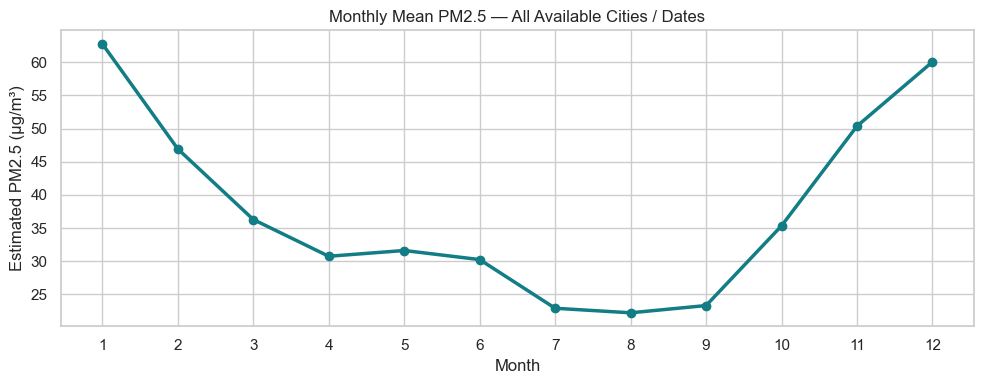

Note: 2026 is partial; month averages combine available observations, not equal full years.


In [17]:
monthly = df.groupby("month")["pm2_5_mean"].mean().reindex(range(1,13))
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.index, monthly.values, marker="o", linewidth=2.5, color="#127d85")
ax.set(xticks=range(1,13), xlabel="Month", ylabel="Estimated PM2.5 (µg/m³)", title="Monthly Mean PM2.5 — All Available Cities / Dates")
plt.tight_layout(); plt.savefig(OUT/"02_monthly_seasonality.png", dpi=160); plt.show()
print("Note: 2026 is partial; month averages combine available observations, not equal full years.")

## 6. Delhi vs Mumbai: recent daily trends

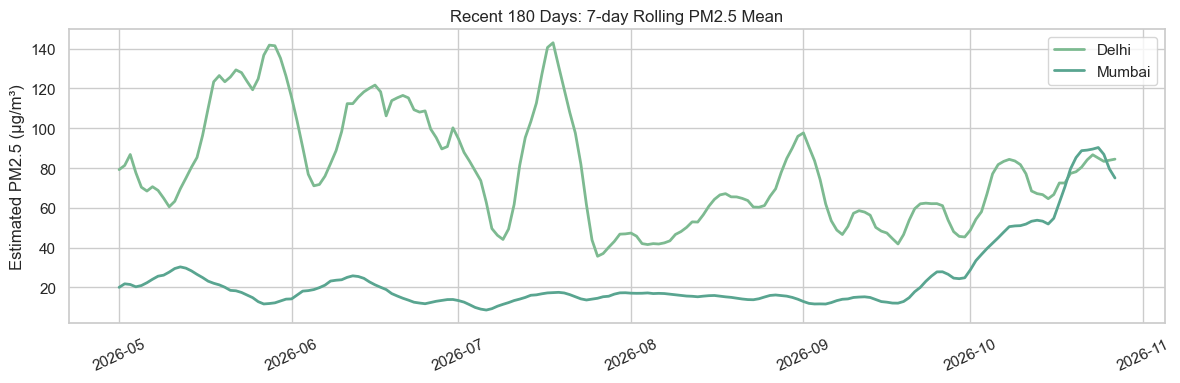

In [18]:
selected = [c for c in ["Delhi", "Mumbai"] if c in df.city.unique()]
fig, ax = plt.subplots(figsize=(12, 4))
for city in selected:
    subset = df[df.city.eq(city)].sort_values("date").tail(180)
    ax.plot(subset.date, subset.pm2_5_mean.rolling(7, min_periods=1).mean(), label=city, linewidth=2)
ax.set(title="Recent 180 Days: 7-day Rolling PM2.5 Mean", ylabel="Estimated PM2.5 (µg/m³)")
ax.legend(); plt.xticks(rotation=25); plt.tight_layout()
plt.savefig(OUT/"03_delhi_mumbai_trends.png", dpi=160); plt.show()

## 7. PM2.5 and PM10 association (not causation)

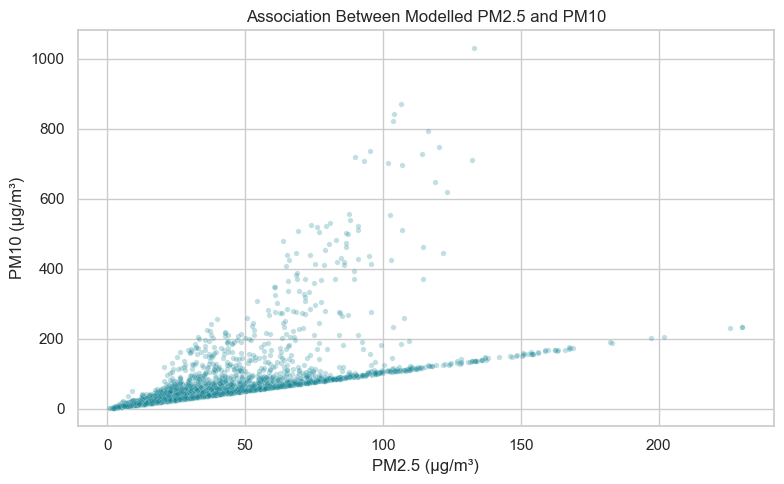

Pearson correlation: 0.604


In [19]:
plot_df = df.dropna(subset=["pm10_mean"]).sample(n=min(4000,len(df.dropna(subset=["pm10_mean"]))), random_state=42)
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=plot_df, x="pm2_5_mean", y="pm10_mean", alpha=.25, s=15, ax=ax, color="#0b8092")
ax.set(title="Association Between Modelled PM2.5 and PM10", xlabel="PM2.5 (µg/m³)", ylabel="PM10 (µg/m³)")
plt.tight_layout(); plt.savefig(OUT/"04_pm25_pm10_scatter.png", dpi=160); plt.show()
print("Pearson correlation:", round(df[["pm2_5_mean", "pm10_mean"]].corr().iloc[0,1],3))

## 8. Derived PM-based index categories (context only)
These are the dataset creator's PM-only index categories. They are **not** full official CPCB AQI categories based on station measurements.

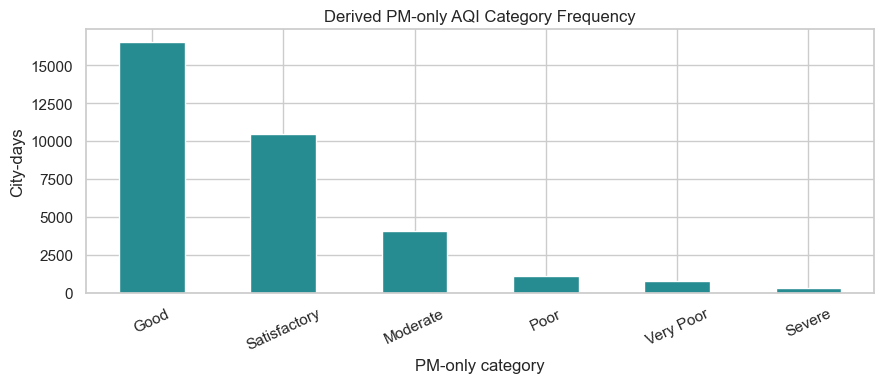

In [20]:
if "india_aqi_pm_category" in df:
    order = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
    counts = df["india_aqi_pm_category"].value_counts().reindex(order).fillna(0)
    fig, ax = plt.subplots(figsize=(9,4))
    counts.plot(kind="bar", ax=ax, color="#268c91")
    ax.set(title="Derived PM-only AQI Category Frequency", ylabel="City-days", xlabel="PM-only category")
    plt.xticks(rotation=25); plt.tight_layout(); plt.savefig(OUT/"05_pm_category_counts.png", dpi=160); plt.show()
else:
    print("PM-only category column unavailable; skipping this chart")

## 9. Machine learning — predict next-day PM2.5
For each city and target date, features use **only earlier observations**. We use a chronological test period and compare against a persistence baseline. Missing dates are reindexed per city, so lag features refer to actual previous calendar days.

In [21]:
all_days = pd.date_range(df.date.min(), df.date.max(), freq="D")
parts = []
for city, group in df.groupby("city"):
    g = group.set_index("date").sort_index().reindex(all_days)
    g.index.name = "date"
    g["city"] = city
    g["target_pm25"] = g["pm2_5_mean"]
    g["lag_1"] = g["pm2_5_mean"].shift(1)
    g["lag_2"] = g["pm2_5_mean"].shift(2)
    g["lag_7"] = g["pm2_5_mean"].shift(7)
    g["rolling_7_prior"] = g["pm2_5_mean"].shift(1).rolling(7, min_periods=7).mean()
    g["month_sin"] = np.sin(2*np.pi*g.index.month/12)
    g["month_cos"] = np.cos(2*np.pi*g.index.month/12)
    parts.append(g.reset_index())
ml = pd.concat(parts, ignore_index=True)
features = ["lag_1", "lag_2", "lag_7", "rolling_7_prior", "month_sin", "month_cos"]
ml = ml.dropna(subset=features+["target_pm25"])
unique_dates = np.sort(ml["date"].unique())
cutoff = unique_dates[int(len(unique_dates)*0.8)]
train = ml[ml.date < cutoff].copy()
test = ml[ml.date >= cutoff].copy()
print("Train:",len(train),"Test:",len(test),"Test starts:",pd.Timestamp(cutoff).date())
assert len(train)>100 and len(test)>30
X_train = pd.get_dummies(train[features+["city"]], columns=["city"])
X_test = pd.get_dummies(test[features+["city"]], columns=["city"]).reindex(columns=X_train.columns, fill_value=0)
y_train, y_test = train.target_pm25, test.target_pm25

Train: 26300 Test: 6600 Test starts: 2026-06-18


## 10. Train Random Forest and compare with persistence

In [22]:
baseline_pred = test["lag_1"].to_numpy()
model = RandomForestRegressor(n_estimators=100, min_samples_leaf=3, max_depth=16, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)
model_pred = model.predict(X_test)

def score(name, pred):
    return {"Model":name, "MAE":mean_absolute_error(y_test,pred), "RMSE":np.sqrt(mean_squared_error(y_test,pred)), "R2":r2_score(y_test,pred)}
metrics = pd.DataFrame([score("Persistence baseline",baseline_pred),score("Random Forest",model_pred)]).set_index("Model")
display(metrics.round(3))
metrics.to_csv(OUT/"model_metrics.csv")
result = test[["date", "city", "target_pm25"]].copy()
result["baseline_prediction"] = baseline_pred
result["rf_prediction"] = model_pred
result.to_csv(OUT/"test_predictions.csv", index=False)
print("Interpretation:", "Random Forest beats persistence on MAE." if metrics.loc["Random Forest","MAE"] < metrics.loc["Persistence baseline","MAE"] else "Persistence is as good as or better than Random Forest on MAE; report this honestly.")

,MAE,RMSE,R2
Model,,,
Persistence baseline,5.712,8.783,0.818
Random Forest,5.617,8.520,0.829


Interpretation: Random Forest beats persistence on MAE.


## 11. Model visualizations and feature importance

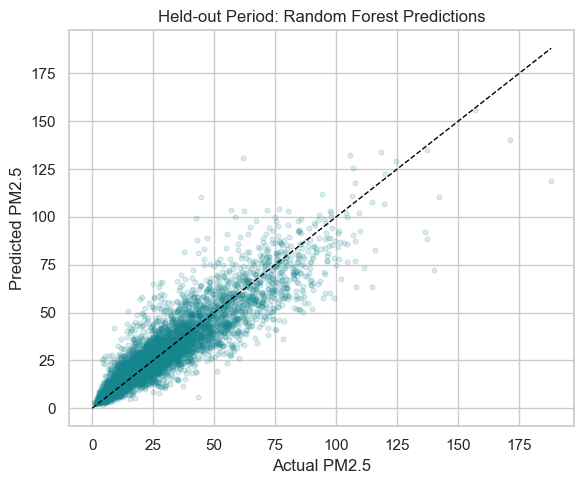

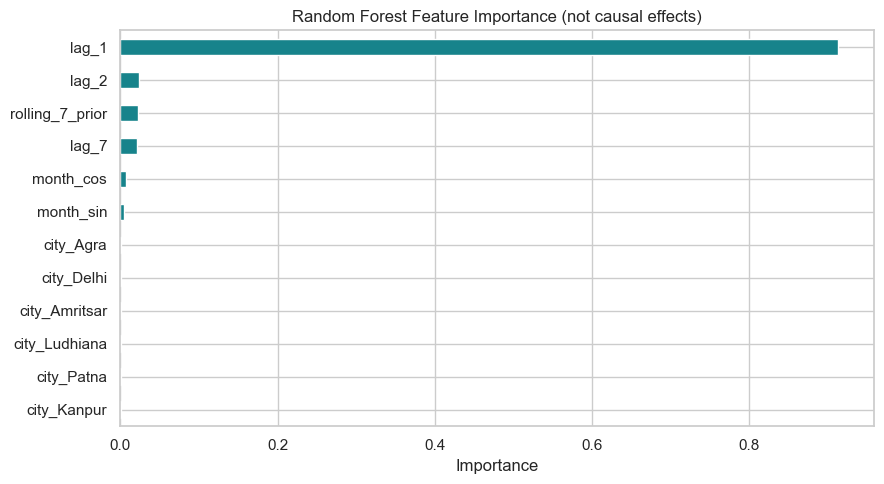

In [23]:
fig, ax = plt.subplots(figsize=(6,5))
ax.scatter(y_test, model_pred, alpha=.15, s=12, color="#15858e")
lim = max(float(np.nanmax(y_test)), float(np.nanmax(model_pred)))
ax.plot([0,lim],[0,lim],"--",color="black",lw=1)
ax.set(xlabel="Actual PM2.5",ylabel="Predicted PM2.5",title="Held-out Period: Random Forest Predictions")
plt.tight_layout();plt.savefig(OUT/"06_actual_vs_predicted.png",dpi=160);plt.show()
importance = pd.Series(model.feature_importances_,index=X_train.columns).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(9,5))
importance.sort_values().plot(kind="barh", ax=ax, color="#17838b")
ax.set(title="Random Forest Feature Importance (not causal effects)", xlabel="Importance")
plt.tight_layout();plt.savefig(OUT/"07_feature_importance.png",dpi=160);plt.show()

## 12. Auto-generated findings (computed, not invented)

In [12]:
print("DATA COVERAGE:", df.date.min().date(),"to",df.date.max().date(),"|",df.city.nunique(),"cities")
print("TOP CITY:", city_avg.index[0], "with mean PM2.5",round(city_avg.iloc[0],1),"µg/m³")
print("HIGHEST MEAN MONTH:",int(monthly.idxmax()),"| LOWEST:",int(monthly.idxmin()))
print("PERSISTENCE MAE:",round(metrics.loc["Persistence baseline","MAE"],2))
print("RANDOM FOREST MAE:",round(metrics.loc["Random Forest","MAE"],2))
print("REMINDER: These are model-based CAMS estimates, not official CPCB station measurements.")

DATA COVERAGE: 2025-01-01 to 2026-10-27 | 50 cities
TOP CITY: Delhi with mean PM2.5 81.3 µg/m³
HIGHEST MEAN MONTH: 1 | LOWEST: 8
PERSISTENCE MAE: 5.71
RANDOM FOREST MAE: 5.62
REMINDER: These are model-based CAMS estimates, not official CPCB station measurements.


## 13. Conclusion and limitations
- Use the **computed** outputs above in your final report; do not invent model accuracy.
- PM2.5 trends can vary substantially across cities and seasons, but this dataset uses modelled grid-cell estimates and may smooth extreme local conditions.
- Compare your model against the persistence baseline; an advanced model is not automatically better.
- The newest data can be provisional. A chronological holdout is necessary to estimate future-date performance.
- **Future improvements:** add meteorological predictors available before forecast time, test multiple seasons, compare against CPCB station measurements, and use rolling-origin validation.

**Citation:** AkshayKarthick, *India Daily Weather & Air Quality (Auto-Updated)*, CC BY 4.0; source data from Open-Meteo / Copernicus CAMS.